---
title: "Springer, Zawodzinski and Gottesfeld (1991): water balance and resistance of a PEM fuel cell membrane"
description: "Whether the membrane results of Table I (alpha = 0.4, R_mem = 0.285 Ohm cm2) follow from the paper's printed membrane model with its printed interface compositions, solved as a conservative finite-volume problem with the fixed-charge concentration as a root-found unknown."
categories: [sec:J, struct:S3, struct:S10, tier:T1, data:tier0, phase:gas-solid]
date: 2026-11-27
---

# Springer, Zawodzinski and Gottesfeld (1991): water balance and resistance of a PEM fuel cell membrane

**Catalog ID:** `J3.6` · **Structures:** `S3` (steady diffusion with a nonlinear
coefficient), `S10` (a flux closure fixed by an algebraic condition) · **Tier:** T1

Springer, Zawodzinski and Gottesfeld built the first water-management model of a
polymer electrolyte fuel cell on membrane properties measured in their own laboratory:
the sorption isotherm, the electro-osmotic drag coefficient, the water diffusion
coefficient and the conductivity of Nafion 117, each as a function of the water content
$\lambda$ (water molecules per sulfonate group). The membrane carries water by drag from
anode to cathode and by back-diffusion the other way; the net flux per proton, $\beta$,
is the paper's headline. This page asks one question that the printed numbers can
decide: at the base case of Table I, do $\alpha$ = 0.4 and $R_{mem}$ = 0.285 Ω cm² follow
from the printed membrane equations with the printed interface water fractions?

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.27.8"  # replaced by the release tag at publication
PYMRM = ">=3.4.1,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J3.6-springer-zawodzinski-gottesfeld"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. pymrm contributes the membrane solve (construct_grad, construct_div, NumJac,
# newton, compute_boundary_values, in model.py) and the checks (find_roots,
# observed_orders); the correlations and the gas side are closed forms.
import contextlib
import io
import math
import re
from dataclasses import dataclass, field, replace
from decimal import Decimal

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (C_REF, Membrane, Scheme, alpha_eq7_xO4, alpha_eq7_xw4, alpha_eq8,
                   closed_const_d, constants, d_kirchhoff, d_lambda, d_poly, d_ratio, drag,
                   lam_eq16, lam_iso, ndrag, psat, sigma, vcell_eq27)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

In a PEM fuel cell the proton-conducting membrane must stay wet: its conductivity
falls steeply as it dries. Protons drag water from anode to cathode, the cathode
produces water, and the resulting gradient drives water back by diffusion. Springer,
Zawodzinski and Gottesfeld (1991) combined their measured membrane properties into a
one-dimensional, isothermal, steady model of the whole cell: gas diffusion through
both electrodes (Eqs. 9 to 14), the membrane water balance (Eqs. 23 and 24), the
membrane resistance (Eq. 26) and a Tafel cathode (Eq. 27). The abstract states the
headline: "The model predicts a net-water-per-proton flux ratio of 0.2 H<sub>2</sub>O/H<sup>+</sup>
under typical operating conditions, which is much less than the measured
electro-osmotic drag coefficient for a fully hydrated membrane" (p. 2334).

The paper prints one numeric table, Table I, the base case at 0.5 A/cm², with the
computed interface compositions, $\alpha$ = 0.4, $\beta$ = 0.2 and $R_{mem}$ = 0.285 Ω cm²
(p. 2338). Everything else is figures. The electrodes cannot be rebuilt: the porosity,
the critical constants and the molar masses of Eq. 10 are not printed. The membrane
can, from the printed interface water fractions $x_{w2}$ and $x_{w3}$, except for one
constant: the dry density over the equivalent weight, $\rho_{dry}/M_m$, appears in
Eqs. 23 and 24 but has no printed value (list of symbols, p. 2341; Table I; Eqs. 19 to 26; the 1155 of p. 2337 is Yeo and Eisenberg's Nafion). This page treats it as the one free
constant and finds the value that gives the printed $\alpha$.

The page complements `J3.4` (Doyle, Fuller and Newman, the lithium-ion P2D model):
both are 1-D electrochemical transport problems with a state-dependent coefficient,
here with the closing flux as an unknown. Out of scope, not judged: the electrodes
(Eqs. 9 to 14), the polarisation curves of Figs. 5 to 9, the drying of the anode at
high current (it needs the $\lambda \le 4$ table of $D_\lambda$, which is not printed),
Fig. 10 and the measured 0.2 H<sub>2</sub>O/H<sup>+</sup> of p. 2340.

## The published model

Membrane properties (pp. 2336 and 2337), with $a = x_w P / P_{sat}$ the water activity
at a membrane face ("The activity in the vapor phase is $x_wP/P_{sat}$", p. 2336):

| Eq. | As printed | Code |
|---|---|---|
| 15 | $\log_{10} P_{sat} = -2.1794 + 0.02953 T - 9.1837\cdot10^{-5} T^2 + 1.4454\cdot10^{-7} T^3$ (atm, °C) | `psat` |
| 16 | $\lambda_{30C} = 0.043 + 17.81 a - 39.85 a^2 + 36.0 a^3$, $0 < a \le 1$ | `lam_eq16` |
| 17 | $\lambda = 14 + 1.4 (a - 1)$ for $1 \le a \le 3$ | `lam_iso` |
| 18 | $n_{drag} = 2.5\lambda/22$ and $N_{w,drag} = n_{drag}\cdot(2I)$ | `ndrag`, `drag` |
| 21 | $D_{\lambda,30C} = \frac{1}{(1+s\lambda)^2}\frac{\lambda}{a(17.81 - 79.70a + 108a^2)} D'$, $s$ = 0.0126 | `d_ratio` |
| 22 | $D_{\lambda>4} = 10^{-6}\exp[2416(\frac{1}{303} - \frac{1}{273+T_{cell}})](2.563 - 0.33\lambda + 0.0264\lambda^2 - 0.000671\lambda^3)$ | `d_lambda` |
| 25 | $\sigma_{30} = 0.005139\lambda - 0.00326$, $\sigma(T_{cell}) = \exp[1268(\frac{1}{303} - \frac{1}{273+T_{cell}})]\sigma_{30}$ | `sigma` |
| 26 | $R_m = \int_0^{t_m} dz/\sigma(\lambda)$ | `Membrane.resistance` |

The membrane water balance on $z$, "a new coordinate, z, fixed to the dry membrane"
(p. 2337), with $I = J/2F$ the H<sub>2</sub> flux (Eq. 1) and $\alpha$ the net water
flux over $I$:

$$N_w = \alpha I = n_{drag}\cdot(2I)\cdot\frac{\lambda}{22} - \frac{\rho_{dry}}{M_m}D_\lambda\frac{d\lambda}{dz} \quad [23],
\qquad \frac{d\lambda}{dz} = \left[2n_{drag}\cdot\frac{\lambda}{22} - \alpha\right]\frac{IM_m}{\rho_{dry}D_\lambda(\lambda)} \quad [24].$$

Eq. 18 has already put $\lambda/22$ into $n_{drag}$, and p. 2340 confirms it: "(The value
of $n_{drag}$ is 1.59 at $\lambda$ = 14.)" ($2.5 \cdot 14/22$). Read literally, Eqs. 23 and
24 multiply by $\lambda/22$ a second time, so the drag per H<sub>2</sub> is
$5\lambda^2/484$ instead of $5\lambda/22$. The page solves the corrected balance

$$\frac{d}{dz}\left[\tfrac{5}{22}\lambda I - c_f D_\lambda(\lambda)\frac{d\lambda}{dz}\right] = 0,
\qquad \lambda(0) = \lambda_2,\ \lambda(t_{mem}) = \lambda_3,\qquad c_f = \rho_{dry}/M_m,$$

with $\lambda_2$ from Eq. 16 at $x_{w2}$ and $\lambda_3$ from Eq. 17 at $x_{w3}$ (the
cathode face is above saturation), and shows separately that the literal reading
cannot carry $\alpha$ = 0.4. Gas side, used only on the printed numbers: Eq. 8 for
$x_{w1}$, Eq. 7 for $x_{w4}$ and $x_{O4}$, Eq. 27 for $V_{cell}$:

$$x_{w1} = \frac{\nu_H x^I_{wA} - \alpha(1 - x^I_{wA})}{x^I_{wA} - \alpha(1 - x^I_{wA}) + \nu_H - 1}\ [8],\qquad
J = j_oP_C\frac{x_{O3}}{1 - x_{liq}}\exp\left[\frac{0.5F}{RT}\eta\right],\ \eta = V_{oc} - V_{cell} - J\cdot R_{mem}\ [27].$$

## Parameters and assumptions

Every printed constant is read from `springer-1991-printed-numbers.csv` into one
dictionary that every function takes, so a mistyped constant is one changed entry.
The page adds four things the paper does not print, each named where it is used:

- $c_f = \rho_{dry}/M_m$: the reference value 1.8e-3 mol/cm³ is a page assumption for
  the R3 profile; the result R4 replaces it by the root $c_f^{\ast}$ that gives $\alpha$ = 0.4.
  Neither is the authors' value.
- $R$ = 8.314 J/(mol K) in Eq. 27 ("R molar gas constant" is listed without a value),
  with $T = 273 + T_{cell}$, the conversion Eqs. 22 and 25 print.
- An equivalent weight of 1100 g/mol only to express $c_f^{\ast}$ as a dry density.
- $t_{mem}$ = 0.0175 cm is taken as the dry thickness in Eq. 26 (the paper does not say
  which); R6 brackets the other reading.

The 30 °C isotherm is used at 80 °C as the paper does ("we are assuming that the 30°C
data applies to membrane equilibrium with water vapor at 80°C", p. 2336). $P_{sat}$ comes
from Eq. 15; Table I's inlet fraction 0.1558 does not equal Eq. 15's $P_{sat}/P$ (R1),
and R4 carries the printed value as a sensitivity.

In [3]:
PN = load_data("springer-1991-printed-numbers.csv", page=PAGE, dtype=str).set_index("item")["printed"].to_dict()
CF_REF = 1.8e-3        # mol/cm3, page assumption (rho_dry/M_m not printed)
RGAS = 8.314           # J/(mol K), page assumption (not printed)
EW = 1100.0            # g/mol, page assumption, only to express c_f* as a density
ROUND = 5e-5           # half a unit of the 4th decimal of x_w2, x_w3 (sensitivity)
ALPHA_BAND = (0.35, 0.45)            # half-unit band of the printed alpha = 0.4
CF_RANGE = (1e-4, 1e-2)              # mol/cm3, physical range scanned for c_f
CF_STOP = (1.2e-3, 2.4e-3)           # the plan's bracket for c_f* (stop rule)
LADDER = (200, 400, 800, 1600, 3200)    # production ladder, extrapolated (rule 36)
V4_LADDER = (24, 48, 96, 192, 384)      # refinement study (V4), even n: lambda(1/2) on a face
N_SCAN = 400                            # grid of the root scans (find_roots)


@dataclass
class Cfg:
    """One configuration of the study; a break row changes one field."""
    pn: dict = field(default_factory=lambda: dict(PN))
    reading: str = "corrected"      # drag in Eqs. 23-24: corrected or literal
    arrh: bool = True               # Arrhenius factor of Eq. 22
    eq20: bool = False              # Eq. 20's extra lambda in the correction factor
    swollen: bool = False           # Eq. 26 with the wet-thickness factor (1 + s lambda)
    t_scale: float = 1.0            # membrane thickness multiplier
    tafel_T_K: float = None         # temperature in Eq. 27 (None: 273 + T_cell)
    scheme: Scheme = Scheme()
    target_scale: float = 1.0       # bordered row alpha - scale * alpha_printed = 0
    comp_dl2: float = 0.0           # relative change of lambda_2 in the round-off companion


C0 = Cfg()

## The data

Two files, each with a `.meta.yaml` sidecar. `springer-1991-printed-numbers.csv` holds
Table I, the correlation constants and the numbers the text states, kept as the printed
strings (read with `dtype=str`) from 300 ppi page images; the scan's text layer is not
used. `fig-reads.csv` holds two figure reads, marked as such: the peak of the
correction factor $D_\lambda/D'$ in Fig. 3 and the midpoint of the 0.5 A/cm² profile in
Fig. 4, with their reading errors. No dataset is borrowed from another page. A third
file, `check_values.csv`, holds values of the page's quantities computed by a second
route (see below); it is not data about the world.

Agreement with a printed number is a count in half-units of its last printed digit:
under 1 means the computed value rounds to the printed entry.

In [4]:
FIG = load_data("fig-reads.csv", page=PAGE, dtype=str).set_index("item")
for f_ in ("springer-1991-printed-numbers.csv", "fig-reads.csv"):
    print(cite_data(load_meta(f_, page=PAGE)))


def hu(x, printed):
    """Signed distance of x from a printed string in half-units of its last digit."""
    unit = float(Decimal(10) ** Decimal(printed).as_tuple().exponent)
    return (x - float(printed)) / (0.5 * unit)

Springer, T. E.; Zawodzinski, T. A.; Gottesfeld, S. (1991) — Journal of the Electrochemical Society 138, 2334-2342 — doi:10.1149/1.2085971 — table
Springer, T. E.; Zawodzinski, T. A.; Gottesfeld, S. (1991) — Journal of the Electrochemical Society 138, 2334-2342 — doi:10.1149/1.2085971 — digitised from Fig. 3 (p. 2337) and Fig. 4 (p. 2338)


## PyMRM implementation

`model.Membrane` solves the conservative balance on $\zeta = z/t_{mem} \in [0, 1]$ with
cell-centred finite volumes. The face flux is
$N = I\,\mathrm{drag}(\lambda_f) - c_f D_\lambda(\lambda_f)\,\partial_\zeta\lambda/t_{mem}$, with
the face gradient from `construct_grad`, the face value $\lambda_f$ from
`interp_cntr_to_stagg` (the arithmetic mean of the two cells; $D_\lambda$ is a smooth
cubic with no jump, so its value at the mean face $\lambda$ is second order) and the
divergence from `construct_div` ($\nu$ = 0, a slab). Both faces carry Dirichlet values,
$\lambda(0) = \lambda_2$ and $\lambda(1) = \lambda_3$, as bc dicts with $a$ = 0, $b$ = 1.
Operators are assembled once per grid. The Jacobian of the flux divergence is
`NumJac((n, 1), axes_diagonals=[0])` (the flux couples neighbouring cells); `pymrm.newton`
solves, and every solve's `success` is checked. $\alpha$ is read from the anode face with
`compute_boundary_values` under the same bc, never from a cell.

The S10 part: with $c_f$ as an extra unknown and the algebraic row $\alpha - 0.4 = 0$,
one bordered Newton system (the tridiagonal block from `NumJac`, the exact $c_f$ column,
the exact $\alpha$ row) gives $c_f^{\ast}$ directly; `pymrm.checks.find_roots` on
$\alpha(c_f) - 0.4$ over the whole range 1e-4 to 1e-2 mol/cm³ is the cross-check, and
must find exactly one root. Every membrane value is computed on five grids (200 to 3200
cells) and extrapolated with `pymrm.checks.observed_orders`.

### Check values

Before any claim, the page's values are checked against values computed by a second
route written apart from this page (quadrature of $z(\lambda)$ with a bracketing root,
no pymrm) at the Table I condition.

In [5]:
def one_root(f, lo, hi, what, log=False, n_scan=24, xtol=1e-15):
    """The single root of f on [lo, hi], or raise."""
    r = find_roots(f, lo, hi, n_scan=n_scan, log=log, xtol=xtol)
    if len(r["roots"]) != 1:
        raise ValueError(f"{what}: {r['message']} on [{lo:g}, {hi:g}]")
    return r["roots"][0]


def band_edge(f, lo, hi, outer):
    """The single root of f on [lo, hi]; when f has no sign change there the band
    reaches ``outer``, the end of the range ("at or beyond the end")."""
    r = find_roots(f, lo, hi, n_scan=24, xtol=1e-14)
    if len(r["roots"]) == 1:
        return r["roots"][0]
    if not r["roots"] and max(f(lo), f(hi)) < 0:
        return outer
    raise ValueError(f"band edge: {r['message']} on [{lo:g}, {hi:g}]")


def base(cfg):
    """Constants and the Table I condition of a configuration."""
    C = constants(cfg.pn)
    T, P = C["T_cell"], C["P_A"]
    ps = psat(T, C)
    return dict(C=C, T=T, P=P, ps=ps, J=C["J"], t=C["t_mem"] * cfg.t_scale,
                l2=lam_iso(C["x_w2"] * P / ps, C), l3=lam_iso(C["x_w3"] * P / ps, C))


def mem(cfg, b, n, l2=None, l3=None, J=None, d_const=None):
    """A Membrane for this configuration (boundary values and current overridable)."""
    return Membrane(n, b["l2"] if l2 is None else l2, b["l3"] if l3 is None else l3,
                    b["J"] if J is None else J, b["T"], b["t"], b["C"], reading=cfg.reading,
                    arrh=cfg.arrh, d_const=d_const, scheme=cfg.scheme)


def ladder(fun, ns=LADDER):
    """Values of fun(n) extrapolated on the ladder, with the relative size of the
    extrapolation step at the finest grid (the grid error left there)."""
    o = observed_orders(lambda n: np.asarray(fun(n), dtype=float), ns)
    ext, fin = np.atleast_1d(o["extrapolated"]), np.atleast_1d(o["values"][-1])
    return ext, float(np.max(np.abs(fin - ext) / np.abs(ext))), o["orders"]


def r_of(m, cfg):
    """Eq. 26 as configured (dry thickness, or the swollen reading in a break row)."""
    return m.resistance(swollen=cfg.swollen)


def alpha_of_cf(cfg, b, n=N_SCAN):
    """alpha(c_f) on one grid, for root scans."""
    m = mem(cfg, b, n)
    return lambda cf: m.solve(cf / C_REF).alpha()


def bordered(cfg, b, alpha, n, u0, **kw):
    """c_f, R and lambda(1/2) with alpha fixed (bordered Newton)."""
    m = mem(cfg, b, n, **kw).solve(u0)
    m.solve_alpha(alpha, u0)
    return m

### The study

`study(cfg)` computes every number the page reports; the break table reruns it with one
defect at a time.

In [6]:
def part_props(cfg, b, M):
    """R1: correlations, against the paper's own statements and Fig. 3."""
    C, pn = b["C"], cfg.pn
    M["r1_psat_80C"] = b["ps"]
    M["r1_xsat_80C"] = b["ps"] / b["P"]
    M["r1_xsat_hu"] = hu(M["r1_xsat_80C"], pn["x_I_w"])
    M["r1_lambda_a1"] = lam_eq16(1.0, C)
    M["r1_lambda_a1_hu"] = hu(M["r1_lambda_a1"], pn["lambda_sat_30C"])
    M["r1_ndrag14"] = ndrag(14.0, C)
    M["r1_ndrag14_hu"] = hu(M["r1_ndrag14"], pn["ndrag_lambda14"])
    M["r1_lambda2"], M["r1_lambda3"] = b["l2"], b["l3"]
    # Eq. 22 at 30 C over lambda 6 to 14 against "1.2 . 10^-6": the extremes (roots of
    # the derivative or the ends) and the lambda range that rounds to 1.2
    p = d_poly(C)
    crit = [r_.real for r_ in p.deriv().roots() if abs(r_.imag) < 1e-12 and 6 < r_.real < 14]
    vals = [p(x) for x in [6.0, 14.0, *crit]]
    M["r1_D30_min"], M["r1_D30_max"] = min(vals), max(vals)
    lvl = float(pn["D_level_30C"]) / 1e-6
    unit = float(Decimal(10) ** Decimal(pn["D_level_30C"]).as_tuple().exponent) / 1e-6
    lam_min = crit[0] if crit else 10.0
    edge = lambda x: p(x) - (lvl + 0.5 * unit)
    M["r1_D30_round_lo"] = band_edge(edge, 6.0, lam_min, 6.0)
    M["r1_D30_round_hi"] = band_edge(edge, lam_min, 14.0, 14.0)
    M["r1_D30_lambda10"] = d_lambda(10.0, 30.0, C, cfg.arrh)
    M["r1_D80_lambda10"] = d_lambda(10.0, b["T"], C, cfg.arrh)
    M["r1_sigma80_lambda14"] = sigma(14.0, b["T"], C)
    # Fig. 3: Eq. 21 (or the Eq. 20 reading) against the read peak at lambda = 3
    r3, r14 = d_ratio(3.0, C, cfg.eq20), d_ratio(14.0, C, cfg.eq20)
    M["r1_Dratio3"], M["r1_Dratio14"] = r3, r14
    fr = FIG.loc["fig3_ratio_peak"]
    M["r1_fig3_dev"] = (r3 - float(fr["value"])) / float(fr["read_error"])
    M["r1_fig3_dev_eq20"] = (d_ratio(3.0, C, True) - float(fr["value"])) / float(fr["read_error"])


def part_gas(cfg, b, M):
    """R2 and R7: alpha from the gas side, relative humidity, V_cell, side claims."""
    C, pn = b["C"], cfg.pn
    xI = C["x_I_w"]
    M["r2_alpha_xw1"] = alpha_eq8(C["x_w1"], xI, C["nu_H"])
    M["r2_alpha_xw4"] = alpha_eq7_xw4(C["x_w4"], xI, C["nu_O"], C["x_ON"])
    M["r2_alpha_xO4"] = alpha_eq7_xO4(C["x_O4"], xI, C["nu_O"], C["x_ON"])
    a3 = [M[f"r2_alpha_{k}"] for k in ("xw1", "xw4", "xO4")]
    M["_r2_inside"] = [1.0 - abs(hu(a, pn["alpha"])) for a in a3]   # > 0: rounds to 0.4
    M["r2_relhum1"], M["r2_relhum4"] = C["x_w1"] / xI, C["x_w4"] / xI
    M["r2_relhum1_hu"] = hu(M["r2_relhum1"], pn["RelHum1"])
    M["r2_relhum4_hu"] = hu(M["r2_relhum4"], pn["RelHum4"])
    TK = cfg.tafel_T_K or 273.0 + b["T"]
    for tag, xl in (("xliq077", C["x_liq4"]), ("xliq0", 0.0)):
        M[f"r7_vcell_{tag}"] = vcell_eq27(C["J"], C["R_mem"], C["x_O3"], xl, C, TK, RGAS)
    M["r7_vcell_hu"] = hu(M["r7_vcell_xliq077"], pn["V_cell"])
    M["r7_vcell_xliq0_hu"] = hu(M["r7_vcell_xliq0"], pn["V_cell"])
    T, t = b["T"], b["t"]
    M["r7_R_uniform14"] = t / sigma(14.0, T, C)
    M["r7_R_uniform15"] = t / sigma(15.0, T, C)
    M["r7_R_uniform14_hu"] = hu(M["r7_R_uniform14"], pn["R_full_hydration"])
    M["r7_R_uniform15_hu"] = hu(M["r7_R_uniform15"], pn["R_full_hydration"])
    M["r7_R_50um"] = 0.005 * cfg.t_scale / sigma(14.0, T, C)
    M["r7_R_50um_margin"] = float(pn["R_50um_bound"]) - M["r7_R_50um"]
    M["r7_jlim"] = C["J"] * C["x_O4"] / (C["x_O4"] - C["x_O3"])
    M["r7_jlim_hu"] = hu(M["r7_jlim"], pn["Jlim_O2"])
    M["r7_o2_drop_pct"] = 100.0 * (C["x_O4"] - C["x_O3"]) / C["x_O4"]
    M["r7_o2_drop_hu"] = hu(M["r7_o2_drop_pct"], pn["O2_drop_pct"])

In [7]:
def part_r3(cfg, b, M):
    """R3: the profile at the assumed c_f, extrapolated; and V3, V4 on it."""
    fun = lambda n: (lambda m: [m.alpha(), r_of(m, cfg), m.lam_mid()])(
        mem(cfg, b, n).solve(CF_REF / C_REF))
    ext, err, _ = ladder(fun)
    M["r3_alpha"], M["r3_R"], M["r3_lam_mid"] = ext
    M["r3_ext_err"] = err
    m = mem(cfg, b, LADDER[-1]).solve(CF_REF / C_REF)
    if m.lam.min() <= float(cfg.pn["eq22_lambda_min"]):
        raise ValueError("lambda falls to 4 or below: Eq. 22 does not hold there")
    f = m.face_flux(m.lam, m.u) * m.q
    M["v3_flux_spread"] = float(np.ptp(f) / abs(f[0]))
    fb0, fb1 = m.boundary_flux()
    M["v3_face_vs_cbv"] = max(abs(fb0 / f[0] - 1), abs(fb1 / f[-1] - 1))
    cache = {n: fun(n) for n in V4_LADDER}
    for j, k in enumerate(("alpha", "R", "lam_mid")):
        oo = observed_orders(lambda n: cache[n][j], V4_LADDER)["orders"]
        M[f"v4_{k}_order_min"], M[f"v4_{k}_order_max"] = min(oo), max(oo)
    vals = np.array([cache[n] for n in V4_LADDER])
    nf = V4_LADDER[-1]
    mc = mem(cfg, b, nf, l2=b["l2"] * (1 + cfg.comp_dl2))
    mc.lam = np.full((nf, 1), b["l3"])                 # another starting state
    d = abs(mc.solve(CF_REF / C_REF).alpha() - vals[-1, 0])
    M["v4_finest_over_roundoff"] = abs(vals[-1, 0] - vals[-2, 0]) / max(d, 1e-16)


def cf_root(cfg, b, alpha):
    """The single c_f in the physical range with alpha(c_f) = alpha (find_roots), or
    None when there is none (then the scan of the whole range shows it)."""
    r = find_roots(lambda cf: alpha_of_cf(cfg, b)(cf) - alpha, *CF_RANGE, n_scan=24,
                   log=True, xtol=1e-16)
    if len(r["roots"]) > 1:
        raise ValueError(f"alpha(c_f) = {alpha}: {r['message']}")
    return r["roots"][0] if r["roots"] else None


def star(cfg, b, alpha, u0, **kw):
    """c_f*, R and lambda(1/2) at a fixed alpha, extrapolated on the ladder."""
    fun = lambda n: (lambda m: [m.c_f, r_of(m, cfg), m.lam_mid(), m.resistance(swollen=True)])(
        bordered(cfg, b, alpha, n, u0, **kw))
    return ladder(fun)

In [8]:
def part_r4(cfg, b, M):
    """R4 and R6: c_f* for the printed alpha, R there, sensitivities, the bracket."""
    a_p = float(cfg.pn["alpha"])
    cf_s = cf_root(cfg, b, a_p)
    if cf_s is None:
        M["_noroot"] = True
        for k in ("r4_cf_star", "r4_rhodry_star", "r4_R_star", "r4_R_hu", "r4_R_gap_pct",
                  "r4_lam_mid_star", "r4_fig4_dev", "r6_R_swollen_star", "r6_bracket_pos"):
            M[k] = float("nan")
        return
    u0 = cf_s / C_REF
    ext, err, _ = star(cfg, b, a_p * cfg.target_scale, u0)
    M["r4_cf_star"], M["r4_R_star"], M["r4_lam_mid_star"], M["r6_R_swollen_star"] = ext
    M["r4_star_ext_err"] = err
    M["r4_rhodry_star"] = M["r4_cf_star"] * EW
    M["r4_bordered_vs_roots"] = abs(bordered(cfg, b, a_p * cfg.target_scale, N_SCAN, u0).c_f / cf_s - 1)
    R_p = float(cfg.pn["R_mem"])
    M["r4_R_hu"] = hu(M["r4_R_star"], cfg.pn["R_mem"])
    M["r4_R_gap_pct"] = 100.0 * (M["r4_R_star"] / R_p - 1.0)
    f4 = FIG.loc["fig4_J0p5_midpoint"]
    M["r4_fig4_dev"] = (M["r4_lam_mid_star"] - float(f4["value"])) / float(f4["read_error"])
    M["r6_bracket_pos"] = (R_p - M["r4_R_star"]) / (M["r6_R_swollen_star"] - M["r4_R_star"])
    # alpha band: R at the two ends (extrapolated), monotone over an 11-point scan
    for tag, a in zip(("lo", "hi"), ALPHA_BAND):
        M[f"r4_R_band_{tag}"] = star(cfg, b, a, u0)[0][1]
    scan = [bordered(cfg, b, a, N_SCAN, u0) for a in np.linspace(*ALPHA_BAND, 11)]
    M["_r4_band_steps"] = np.diff([r_of(m, cfg) for m in scan])
    # rounding of x_w2, x_w3 and the printed x^I in place of Eq. 15 (all re-rooted)
    C, P, ps = b["C"], b["P"], b["ps"]
    sens = [M["r4_R_band_lo"], M["r4_R_band_hi"]]
    for s2 in (-1, 1):
        for s3 in (-1, 1):
            kw = dict(l2=lam_iso((C["x_w2"] + s2 * ROUND) * P / ps, C),
                      l3=lam_iso((C["x_w3"] + s3 * ROUND) * P / ps, C))
            sens.append(star(cfg, b, a_p, u0, **kw)[0][1])
    kw = dict(l2=lam_iso(C["x_w2"] / C["x_I_w"], C), l3=lam_iso(C["x_w3"] / C["x_I_w"], C))
    M["r4_R_printed_xI"] = star(cfg, b, a_p, u0, **kw)[0][1]
    sens.append(M["r4_R_printed_xI"])
    M["r4_sens_max_R"] = max(sens)
    M["_r4_sens_below"] = [R_p - r_ for r_ in sens]
    # diagnostic: lambda_2 that gives the printed R at the printed alpha (rule 16: no
    # cause is named; it is the size of the change that would be needed)
    def l2_root(n):
        f = lambda l2: r_of(bordered(cfg, b, a_p, n, u0, l2=l2), cfg) - R_p
        return one_root(f, 4.05, 0.5 * (b["l2"] + b["l3"]), "lambda_2 for the printed R",
                        n_scan=8, xtol=1e-13)
    try:      # lambda_2 above 4 (Eq. 22) and up to midway to lambda_3; none: nan
        M["r6_lambda2_for_R"] = ladder(l2_root)[0][0]
    except ValueError:
        M["r6_lambda2_for_R"] = float("nan")


def part_r5(cfg, b, M):
    """R5: the literal drag of Eqs. 23-24, scanned over the whole c_f range."""
    lit = replace(cfg, reading="literal")
    C = b["C"]
    M["r5_literal_bound"] = drag(b["l2"], C, "literal")
    f = alpha_of_cf(lit, b)
    cfs = np.geomspace(*CF_RANGE, 25)
    a_lit = np.array([f(cf) for cf in cfs])
    M["r5_literal_alpha_max"] = float(a_lit.max())
    M["r5_literal_excess"] = M["r5_literal_alpha_max"] - M["r5_literal_bound"]
    a_p = float(cfg.pn["alpha"])
    r = find_roots(lambda cf: f(cf) - a_p, *CF_RANGE, n_scan=25, log=True, xtol=1e-16)
    M["r5_literal_n_roots"] = len(r["roots"])
    M["_r5_margin"] = float(np.min(np.abs(a_lit - a_p)))

In [9]:
def part_v12(cfg, b, M):
    """V1 (constant D, closed form) and V2 (zero current, Kirchhoff)."""
    C, T, t = b["C"], b["T"], b["t"]
    D10 = d_lambda(10.0, T, C, cfg.arrh)
    I = b["J"] / (2.0 * C["F"])
    kd = 2.0 * C["eq18_ndrag_sat"] / C["eq18_lambda_ref"]
    M["v1_pe"] = kd * I * t / (CF_REF * D10)
    a_cc, lam_cc = closed_const_d(b["l2"], b["l3"], kd, M["v1_pe"])
    M["v1_alpha_cc"], M["v1_lam_mid_cc"] = a_cc, float(lam_cc(0.5))
    fun = lambda n: (lambda m: [m.alpha(), m.lam_mid()])(
        mem(cfg, b, n, d_const=D10).solve(CF_REF / C_REF))
    ext, _, _ = ladder(fun)
    M["v1_gap_alpha"] = abs(ext[0] / a_cc - 1)
    M["v1_gap_lam_mid"] = abs(ext[1] / M["v1_lam_mid_cc"] - 1)
    # exact by construction: constant D and no current give a linear profile, which the
    # scheme reproduces on any grid (rule 10)
    m = mem(cfg, b, 8, J=0.0, d_const=D10).solve(CF_REF / C_REF)
    lin = b["l2"] + (b["l3"] - b["l2"]) * m.x_c
    M["v1_exact_case_gap"] = float(np.max(np.abs(m.lam.ravel() - lin)))
    # V2: zero current, the flux is -(c_f/t) int D dlambda (Kirchhoff, closed form)
    M["v2_N0_closed"] = -(CF_REF / t) * d_kirchhoff(b["l2"], b["l3"], T, C, cfg.arrh)
    fun0 = lambda n: [mem(cfg, b, n, J=0.0).solve(CF_REF / C_REF).boundary_flux()[0]]
    M["v2_N0_gap"] = abs(ladder(fun0)[0][0] / M["v2_N0_closed"] - 1)
    mu = mem(cfg, b, 64, l2=10.0, l3=10.0, J=0.0).solve(CF_REF / C_REF)
    M["v2_uniform_flux"] = float(np.max(np.abs(mu.face_flux(mu.lam, mu.u))))


def study(cfg):
    """Every number the page reports, for one configuration."""
    M = {}
    b = base(cfg)
    part_props(cfg, b, M)
    part_gas(cfg, b, M)
    part_r3(cfg, b, M)
    part_r4(cfg, b, M)
    part_r5(cfg, b, M)
    part_v12(cfg, b, M)
    return M

In [10]:
M = study(C0)
b0 = base(C0)
I0 = b0["J"] / (2.0 * b0["C"]["F"])
CV = {
    "psat_80C_atm": M["r1_psat_80C"], "xsat_80C_3atm": M["r1_xsat_80C"],
    "lambda_eq16_a1": M["r1_lambda_a1"], "ndrag_lambda14": M["r1_ndrag14"],
    "lambda2_anode": M["r1_lambda2"], "lambda3_cathode": M["r1_lambda3"],
    "Dlam_80C_lambda10_cm2s": M["r1_D80_lambda10"], "Dlam_30C_lambda10_cm2s": M["r1_D30_lambda10"],
    "sigma_80C_lambda14_Scm": M["r1_sigma80_lambda14"], "Rmem_uniform_lambda14": M["r7_R_uniform14"],
    "Rmem_uniform_lambda15": M["r7_R_uniform15"], "Rmem_uniform_lambda14_50um": M["r7_R_50um"],
    "drag_literal_max_alpha": M["r5_literal_bound"], "Dratio_eq21_lambda3": M["r1_Dratio3"],
    "Dratio_eq21_lambda14": M["r1_Dratio14"], "alpha_from_xw1_eq8": M["r2_alpha_xw1"],
    "alpha_from_xw4_eq7": M["r2_alpha_xw4"], "alpha_from_xO4_eq7": M["r2_alpha_xO4"],
    "relhum1_printed_xsat": M["r2_relhum1"], "relhum4_printed_xsat": M["r2_relhum4"],
    "Vcell_eq27_xliq0": M["r7_vcell_xliq0"], "Vcell_eq27_xliq0.077": M["r7_vcell_xliq077"],
    "Jlim_O2_linear_extrap": M["r7_jlim"], "alpha_cfref": M["r3_alpha"],
    "beta_cfref": 0.5 * M["r3_alpha"], "Rmem_cfref_ohmcm2": M["r3_R"],
    "lambda_mid_cfref": M["r3_lam_mid"], "cf_star_alpha0p4_molcm3": M["r4_cf_star"],
    "rhodry_star_at_EW1100_gcm3": M["r4_rhodry_star"], "Rmem_cfstar_ohmcm2": M["r4_R_star"],
    "Pe_constD": M["v1_pe"], "alpha_constD_closed": M["v1_alpha_cc"],
    "lambda_mid_constD_closed": M["v1_lam_mid_cc"], "N0_zero_current_molcm2s": M["v2_N0_closed"],
    "lambda2_for_R0p285": M["r6_lambda2_for_R"]}
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(CV, page=PAGE)
say("Check values: <<n:d>> of <<t:d>> rows agree, each inside its own tolerance "
    "(rtol 1e-11 to 1e-8); worst relative deviation <<w:.1e>>.",
    n=len(DEV), t=len(CV), w=max(abs(v) for v in DEV.values()))

Check values: 35 of 35 rows agree, each inside its own tolerance (rtol 1e-11 to 1e-8); worst relative deviation 5.7e-11.

## Results

### R1: the property correlations against the paper's own statements

In [11]:
say("Eq. 16 at $a$ = 1 gives $\\lambda$ = <<la:.3f>> (text: 14, <<lah:.3f>> half-units); "
    "Eq. 18 gives $n_{drag}(14)$ = <<nd:.4f>> (p. 2340: 1.59, <<ndh:.2f>> half-units). At 80 °C "
    "Eq. 15 gives $P_{sat}$ = <<ps:.6f>> atm, so $P_{sat}/P$ = <<xs:.6f>>, <<xsh:.2f>> half-units of the last digit "
    "of Table I's 0.1558: the printed inlet fraction does not round from Eq. 15. The interface "
    "values are $\\lambda_2$ = <<l2:.4f>> (Eq. 16 at $x_{w2}$) and $\\lambda_3$ = <<l3:.4f>> (Eq. 17 "
    "at $x_{w3}$, above saturation).",
    la=M["r1_lambda_a1"], lah=M["r1_lambda_a1_hu"], nd=M["r1_ndrag14"], ndh=M["r1_ndrag14_hu"],
    ps=M["r1_psat_80C"], xs=M["r1_xsat_80C"], xsh=M["r1_xsat_hu"], l2=M["r1_lambda2"], l3=M["r1_lambda3"])
say("p. 2340: \"the effect D becomes almost independent of water content (Fig. 3), at a level of "
    "1.2 · 10<sup>-6</sup> cm<sup>2</sup>/s\". Eq. 22 at 30 °C runs from <<mn:.4f>>e-6 to <<mx:.4f>>e-6 "
    "cm²/s over $\\lambda$ = 6 to 14 and rounds to 1.2e-6 only for $\\lambda$ between <<lo:.3f>> "
    "and <<hi:.3f>> (roots of the band edge 1.25e-6).",
    mn=M["r1_D30_min"], mx=M["r1_D30_max"], lo=M["r1_D30_round_lo"], hi=M["r1_D30_round_hi"])
say("**Fig. 3 decides between Eqs. 20 and 21.** Eq. 21 gives $D_\\lambda/D'$ = <<r3:.4f>> at "
    "$\\lambda$ = 3, <<d:.2f>> reading errors from the read peak of the dotted curve; Eq. 20, with "
    "its extra factor $\\lambda$, would be <<d20:.0f>> reading errors away (off the 0 to 6 axis). "
    "The page uses Eq. 21, which is also what re-deriving Eq. 20 gives.",
    r3=M["r1_Dratio3"], d=M["r1_fig3_dev"], d20=M["r1_fig3_dev_eq20"])

Eq. 16 at $a$ = 1 gives $\lambda$ = 14.003 (text: 14, 0.006 half-units); Eq. 18 gives $n_{drag}(14)$ = 1.5909 (p. 2340: 1.59, 0.18 half-units). At 80 °C Eq. 15 gives $P_{sat}$ = 0.466926 atm, so $P_{sat}/P$ = 0.155642, -3.16 half-units of the last digit of Table I's 0.1558: the printed inlet fraction does not round from Eq. 15. The interface values are $\lambda_2$ = 4.6793 (Eq. 16 at $x_{w2}$) and $\lambda_3$ = 14.6931 (Eq. 17 at $x_{w3}$, above saturation).

p. 2340: "the effect D becomes almost independent of water content (Fig. 3), at a level of 1.2 · 10<sup>-6</sup> cm<sup>2</sup>/s". Eq. 22 at 30 °C runs from 1.2316e-6 to 1.3885e-6 cm²/s over $\lambda$ = 6 to 14 and rounds to 1.2e-6 only for $\lambda$ between 8.631 and 12.339 (roots of the band edge 1.25e-6).

**Fig. 3 decides between Eqs. 20 and 21.** Eq. 21 gives $D_\lambda/D'$ = 2.4252 at $\lambda$ = 3, 0.10 reading errors from the read peak of the dotted curve; Eq. 20, with its extra factor $\lambda$, would be 97 reading errors away (off the 0 to 6 axis). The page uses Eq. 21, which is also what re-deriving Eq. 20 gives.

### R2: the gas side of Table I closes on alpha

In [12]:
_n_r2 = int(sum(v > 0 for v in M["_r2_inside"]))
say("Solved for $\\alpha$ with the printed $x^I_w$ = 0.1558, Eq. 8 at $x_{w1}$ gives <<a1:.4f>>, "
    "Eq. 7 at $x_{w4}$ <<a4:.4f>> and at $x_{O4}$ <<ao:.4f>>: <<n:d>> of <<t:d>> round to Table I's "
    "$\\alpha$ = 0.4. The relative humidities are $x_{w1}/x^I$ = <<h1:.6f>> (<<h1h:.2f>> half-units "
    "from Rel Hum<sub>1</sub> = 0.6515) and $x_{w4}/x^I$ = <<h4:.6f>> (<<h4h:.2f>> half-units from "
    "Rel Hum<sub>4</sub> = 1.4535): the second is a few units off in its fourth decimal.",
    a1=M["r2_alpha_xw1"], a4=M["r2_alpha_xw4"], ao=M["r2_alpha_xO4"], n=_n_r2, t=len(M["_r2_inside"]),
    h1=M["r2_relhum1"], h1h=M["r2_relhum1_hu"], h4=M["r2_relhum4"], h4h=M["r2_relhum4_hu"])

Solved for $\alpha$ with the printed $x^I_w$ = 0.1558, Eq. 8 at $x_{w1}$ gives 0.3993, Eq. 7 at $x_{w4}$ 0.3980 and at $x_{O4}$ 0.3968: 3 of 3 round to Table I's $\alpha$ = 0.4. The relative humidities are $x_{w1}/x^I$ = 0.651476 (-0.47 half-units from Rel Hum<sub>1</sub> = 0.6515) and $x_{w4}/x^I$ = 1.453145 (-7.10 half-units from Rel Hum<sub>4</sub> = 1.4535): the second is a few units off in its fourth decimal.

### R3: the membrane profile, solved with pymrm

At the assumed $c_f$ = 1.8e-3 mol/cm³ (not the authors' value), extrapolated on the
ladder. The plot shows the profile and the split of the constant net flux into drag and
back-diffusion along the membrane; the Fig. 4 read is overlaid but carries no weight
(its caption holds gas flows constant at $\nu_H$ = 1 at 1 A/cm², so the 0.5 A/cm² curve
is at $\nu_H$ = 2 by the flow rule of p. 2338, against Table I's 4).

At $c_f$ = 1.8e-3 mol/cm³: $\alpha$ = 0.32164 ($\beta$ = 0.16082), $R_{mem}$ = 0.27635 Ω cm², $\lambda(t_{mem}/2)$ = 7.7497.

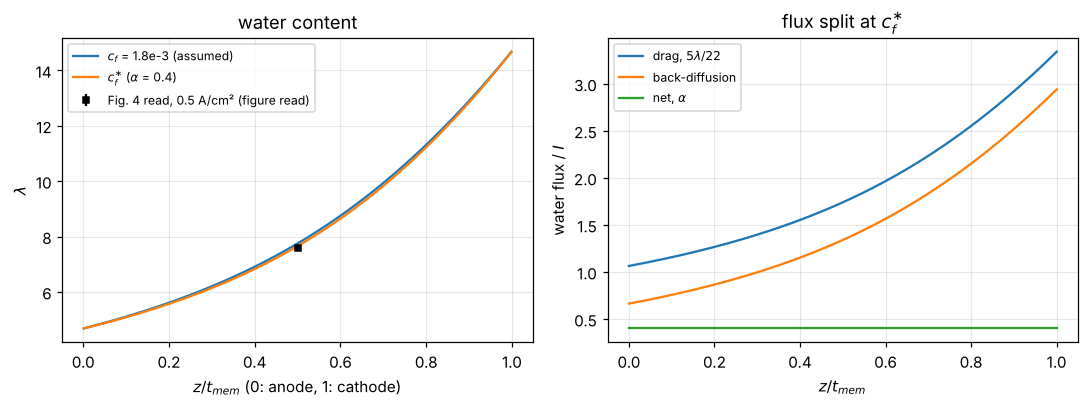

In [13]:
say("At $c_f$ = 1.8e-3 mol/cm³: $\\alpha$ = <<a:.5f>> ($\\beta$ = <<be:.5f>>), $R_{mem}$ = <<R:.5f>> "
    "Ω cm², $\\lambda(t_{mem}/2)$ = <<lm:.4f>>.",
    a=M["r3_alpha"], be=0.5 * M["r3_alpha"], R=M["r3_R"], lm=M["r3_lam_mid"])
_m_ref = mem(C0, b0, 400).solve(CF_REF / C_REF)
_m_star = bordered(C0, b0, float(PN["alpha"]), 400, M["r4_cf_star"] / C_REF)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for m_, lab in ((_m_ref, "$c_f$ = 1.8e-3 (assumed)"), (_m_star, "$c_f^{\\ast}$ ($\\alpha$ = 0.4)")):
    ax[0].plot(m_.x_c, m_.lam.ravel(), label=lab)
_f4 = FIG.loc["fig4_J0p5_midpoint"]
ax[0].errorbar([0.5], [float(_f4["value"])], yerr=[float(_f4["read_error"])], fmt="ks", ms=4,
               label="Fig. 4 read, 0.5 A/cm² (figure read)")
ax[0].set(xlabel="$z/t_{mem}$ (0: anode, 1: cathode)", ylabel="$\\lambda$", title="water content")
ax[0].legend(fontsize=8)
lf = _m_star.face_lambda(_m_star.lam)
dr = drag(lf, b0["C"]) * np.ones_like(lf)
net = _m_star.face_flux(_m_star.lam, _m_star.u) * _m_star.q / _m_star.I
ax[1].plot(_m_star.x_f, dr, label="drag, $5\\lambda/22$")
ax[1].plot(_m_star.x_f, dr - net, label="back-diffusion")
ax[1].plot(_m_star.x_f, net, label="net, $\\alpha$")
ax[1].set(xlabel="$z/t_{mem}$", ylabel="water flux / $I$", title="flux split at $c_f^{\\ast}$")
ax[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### R4: the fixed-charge concentration for the printed alpha, and the resistance there

In [14]:
_n_sens = int(sum(v > 0 for v in M["_r4_sens_below"]))
say("The bordered Newton solve with the row $\\alpha$ - 0.4 = 0 gives $c_f^{\\ast}$ = <<cf:.5e>> mol/cm³ "
    "(a dry density of <<rho:.4f>> g/cm³ at an equivalent weight of 1100, a page assumption); "
    "`find_roots` finds the same single root on 1e-4 to 1e-2 mol/cm³ to <<g:.0e>> on the same "
    "grid. There $R_{mem}$ = <<R:.5f>> Ω cm², <<pct:.2f>> % against the printed 0.285, which is "
    "<<h:.1f>> half-units of its last digit. Over the half-unit band of the printed $\\alpha$ "
    "(0.35 to 0.45) $R_{mem}$ rises from <<lo:.5f>> to <<hi:.5f>> (<<nm:d>> of <<nt:d>> steps of an "
    "11-point scan rise); rounding $x_{w2}$ "
    "and $x_{w3}$ by half a unit and using the printed $x^I_w$ = 0.1558 for $P_{sat}/P$ (which "
    "gives <<px:.5f>>) keep it below 0.285: <<n:d>> of <<t:d>> cases, largest <<mx:.5f>>. At "
    "$c_f^{\\ast}$, $\\lambda(t_{mem}/2)$ = <<lm:.3f>>, <<f4:.1f>> reading errors from the Fig. 4 read "
    "(illustrative only).",
    cf=M["r4_cf_star"], rho=M["r4_rhodry_star"], g=max(M["r4_bordered_vs_roots"], 1e-16),
    R=M["r4_R_star"], pct=M["r4_R_gap_pct"], h=M["r4_R_hu"], lo=M["r4_R_band_lo"],
    hi=M["r4_R_band_hi"], px=M["r4_R_printed_xI"], n=_n_sens, t=len(M["_r4_sens_below"]),
    mx=M["r4_sens_max_R"], lm=M["r4_lam_mid_star"], f4=M["r4_fig4_dev"],
    nm=int(sum(v > 0 for v in M["_r4_band_steps"])), nt=len(M["_r4_band_steps"]))

The bordered Newton solve with the row $\alpha$ - 0.4 = 0 gives $c_f^{\ast}$ = 1.69418e-03 mol/cm³ (a dry density of 1.8636 g/cm³ at an equivalent weight of 1100, a page assumption); `find_roots` finds the same single root on 1e-4 to 1e-2 mol/cm³ to 5e-14 on the same grid. There $R_{mem}$ = 0.27875 Ω cm², -2.19 % against the printed 0.285, which is -12.5 half-units of its last digit. Over the half-unit band of the printed $\alpha$ (0.35 to 0.45) $R_{mem}$ rises from 0.27718 to 0.28048 (10 of 10 steps of an 11-point scan rise); rounding $x_{w2}$ and $x_{w3}$ by half a unit and using the printed $x^I_w$ = 0.1558 for $P_{sat}/P$ (which gives 0.27915) keep it below 0.285: 7 of 7 cases, largest 0.28048. At $c_f^{\ast}$, $\lambda(t_{mem}/2)$ = 7.654, 0.8 reading errors from the Fig. 4 read (illustrative only).

### R5: the literal Eq. 24 cannot carry the printed alpha

Read literally, the drag per H<sub>2</sub> is $5\lambda^2/484$. The balance then has a
fixed point where drag equals $\alpha$: a profile that rises from $\lambda_2$ to
$\lambda_3$ needs $d\lambda/dz > 0$ at $\lambda_2$, so $\alpha < 5\lambda_2^2/484$ for any
$\rho_{dry}/M_m$ and any $D_\lambda > 0$ (a structural bound, no break row can move it).

In [15]:
say("With $\\lambda_2$ = <<l2:.4f>> the bound is $\\alpha$ < <<bd:.4f>>. The scan of the literal "
    "reading over $c_f$ = 1e-4 to 1e-2 mol/cm³ (25 points, pymrm solves) reaches at most "
    "$\\alpha$ = <<am:.4f>>, the bound itself as $c_f$ goes to zero, and has <<nr:d>> roots of $\\alpha$ = 0.4: the literal Eqs. 23 and 24 "
    "cannot give Table I for any value of the unprinted constant.",
    l2=M["r1_lambda2"], bd=M["r5_literal_bound"], am=M["r5_literal_alpha_max"],
    nr=M["r5_literal_n_roots"])

With $\lambda_2$ = 4.6793 the bound is $\alpha$ < 0.2262. The scan of the literal reading over $c_f$ = 1e-4 to 1e-2 mol/cm³ (25 points, pymrm solves) reaches at most $\alpha$ = 0.2262, the bound itself as $c_f$ goes to zero, and has 0 roots of $\alpha$ = 0.4: the literal Eqs. 23 and 24 cannot give Table I for any value of the unprinted constant.

### R6: the thickness convention brackets the printed resistance

Eq. 26 integrates $dz/\sigma$ on the dry coordinate. If $t_{mem}$ = 0.0175 cm is instead
a wet thickness reached by the swelling $(1 + s\lambda)$, the resistance is
$\int (1 + s\lambda)\,dz/\sigma$. The paper does not say which; the page does not name a
cause for the gap (rule 16).

In [16]:
say("At $c_f^{\\ast}$ the dry reading gives <<rd:.5f>> and the swollen reading <<rs:.5f>> Ω cm²; the "
    "printed 0.285 lies at <<pos:.3f>> of the way between them. For comparison, keeping "
    "$\\alpha$ = 0.4 and re-rooting $c_f$, the printed 0.285 would need $\\lambda_2$ = <<l2r:.4f>> "
    "instead of <<l2:.4f>>.",
    rd=M["r4_R_star"], rs=M["r6_R_swollen_star"], pos=M["r6_bracket_pos"],
    l2r=M["r6_lambda2_for_R"], l2=M["r1_lambda2"])

At $c_f^{\ast}$ the dry reading gives 0.27875 and the swollen reading 0.30470 Ω cm²; the printed 0.285 lies at 0.241 of the way between them. For comparison, keeping $\alpha$ = 0.4 and re-rooting $c_f$, the printed 0.285 would need $\lambda_2$ = 4.5575 instead of 4.6793.

### R7: the printed side claims

In [17]:
say("**Cell voltage.** Eq. 27 with Table I's $R_{mem}$ and $x_{O3}$ and $x_{liq}$ = 0.077 (the only "
    "printed liquid fraction, given for interface 4) gives $V_{cell}$ = <<v:.5f>> V, <<vh:.2f>> "
    "half-units from 0.668; with $x_{liq}$ = 0 it gives <<v0:.5f>> V (<<v0h:.1f>> half-units).",
    v=M["r7_vcell_xliq077"], vh=M["r7_vcell_hu"], v0=M["r7_vcell_xliq0"], v0h=M["r7_vcell_xliq0_hu"])
say("**Full hydration.** p. 2339: \"near 14 water molecules per membrane charge site throughout "
    "its thickness, and the resistance approaches 0.13 Ω-cm<sup>2</sup>\". A uniform $\\lambda$ = 14 "
    "gives <<r14:.4f>> Ω cm² (<<r14h:.1f>> half-units), $\\lambda$ = 15 gives <<r15:.4f>> "
    "(<<r15h:.1f>>). **Thin membrane.** p. 2340: \"With the thin 50 µm membrane, not only is the "
    "resistance less than 0.05 Ω-cm<sup>2</sup>\": uniform $\\lambda$ = 14 gives <<r50:.4f>>, "
    "<<m50:.4f>> below 0.05. **Oxygen.** p. 2338: the O<sub>2</sub> pressure \"has dropped (at 0.5 "
    "A/cm<sup>2</sup>) only by about 5% across the cathode\" (<<o2:.2f>> % from $x_{O3}$ and "
    "$x_{O4}$) and \"the limiting current set by oxygen diffusion through the cathode is about 10 "
    "A/cm<sup>2</sup>\": a linear extrapolation gives <<jl:.3f>> A/cm².",
    r14=M["r7_R_uniform14"], r14h=M["r7_R_uniform14_hu"], r15=M["r7_R_uniform15"],
    r15h=M["r7_R_uniform15_hu"], r50=M["r7_R_50um"], m50=M["r7_R_50um_margin"],
    o2=M["r7_o2_drop_pct"], jl=M["r7_jlim"])

**Cell voltage.** Eq. 27 with Table I's $R_{mem}$ and $x_{O3}$ and $x_{liq}$ = 0.077 (the only printed liquid fraction, given for interface 4) gives $V_{cell}$ = 0.66844 V, 0.88 half-units from 0.668; with $x_{liq}$ = 0 it gives 0.66357 V (-8.9 half-units).

**Full hydration.** p. 2339: "near 14 water molecules per membrane charge site throughout its thickness, and the resistance approaches 0.13 Ω-cm<sup>2</sup>". A uniform $\lambda$ = 14 gives 0.1408 Ω cm² (2.2 half-units), $\lambda$ = 15 gives 0.1310 (0.2). **Thin membrane.** p. 2340: "With the thin 50 µm membrane, not only is the resistance less than 0.05 Ω-cm<sup>2</sup>": uniform $\lambda$ = 14 gives 0.0402, 0.0098 below 0.05. **Oxygen.** p. 2338: the O<sub>2</sub> pressure "has dropped (at 0.5 A/cm<sup>2</sup>) only by about 5% across the cathode" (5.27 % from $x_{O3}$ and $x_{O4}$) and "the limiting current set by oxygen diffusion through the cathode is about 10 A/cm<sup>2</sup>": a linear extrapolation gives 9.480 A/cm².

## Validation

None of these uses the paper's numbers.

In [18]:
say("**V1 constant $D$, linear drag.** With $D = D_\\lambda(10)$ at 80 °C the balance has the "
    "closed form $\\lambda = \\alpha/k + K e^{Pe\\,\\zeta}$ with $k$ = 5/22 (Pe = <<pe:.4f>>): $\\alpha$ = <<a:.6f>>, "
    "$\\lambda(1/2)$ = <<lm:.5f>>. The extrapolated pymrm solve meets them to <<ga:.0e>> and "
    "<<gm:.0e>> (relative). With no current the exact profile is linear and the scheme "
    "reproduces it to <<ex:.0e>> on 8 cells (exact by construction).",
    pe=M["v1_pe"], a=M["v1_alpha_cc"], lm=M["v1_lam_mid_cc"], ga=max(M["v1_gap_alpha"], 1e-16),
    gm=max(M["v1_gap_lam_mid"], 1e-16), ex=max(M["v1_exact_case_gap"], 1e-16))
say("**V2 zero current.** The flux is then $-(c_f/t)\\int_{\\lambda_2}^{\\lambda_3} D_\\lambda d\\lambda$ "
    "= <<n0:.5e>> mol/(cm² s) (Kirchhoff, closed form); the extrapolated pymrm face flux meets it "
    "to <<g0:.0e>>. A uniform $\\lambda$ carries no flux: zero on every face to the Newton tolerance "
    "(here <<u:.0e>> in units of $c_{ref}D_{unit}/t_{mem}$, with $c_{ref}$ = 1 mmol/cm³ and "
    "$D_{unit}$ = 1e-6 cm²/s).",
    n0=M["v2_N0_closed"], g0=max(M["v2_N0_gap"], 1e-16), u=max(M["v2_uniform_flux"], 1e-17))
say("**V3 discrete water balance.** On 3200 cells the face flux is constant across all faces to "
    "<<sp:.0e>> relative (Newton tolerance 1e-11 on $\\lambda$), and the anode and cathode fluxes "
    "from `compute_boundary_values` equal the operator's face fluxes to <<cb:.0e>>.",
    sp=max(M["v3_flux_spread"], 1e-16), cb=max(M["v3_face_vs_cbv"], 1e-16))
say("**V4 refinement.** On 24 to 384 cells the observed orders of $\\alpha$, $R_{mem}$ and "
    "$\\lambda(1/2)$ lie between <<omin:.4f>> and <<omax:.4f>> (theory 2); the finest difference "
    "is <<rf:.1e>> times its round-off companion (the same solve from another starting state). "
    "On the production ladder the extrapolation changes the 3200-cell values by at most "
    "<<e3:.1e>> (R3) and <<e4:.1e>> (R4) relative.",
    omin=min(M[f"v4_{k}_order_min"] for k in ("alpha", "R", "lam_mid")),
    omax=max(M[f"v4_{k}_order_max"] for k in ("alpha", "R", "lam_mid")),
    rf=M["v4_finest_over_roundoff"], e3=M["r3_ext_err"], e4=M["r4_star_ext_err"])
say("**V5 second route.** <<n:d>> values from a route that shares no code with this page "
    "(quadrature of $z(\\lambda)$, no pymrm) agree, each inside its own tolerance.", n=len(DEV))

**V1 constant $D$, linear drag.** With $D = D_\lambda(10)$ at 80 °C the balance has the closed form $\lambda = \alpha/k + K e^{Pe\,\zeta}$ with $k$ = 5/22 (Pe = 1.5021): $\alpha$ = 0.411561, $\lambda(1/2)$ = 7.88970. The extrapolated pymrm solve meets them to 1e-11 and 8e-13 (relative). With no current the exact profile is linear and the scheme reproduces it to 2e-15 on 8 cells (exact by construction).

**V2 zero current.** The flux is then $-(c_f/t)\int_{\lambda_2}^{\lambda_3} D_\lambda d\lambda$ = -4.11501e-06 mol/(cm² s) (Kirchhoff, closed form); the extrapolated pymrm face flux meets it to 1e-13. A uniform $\lambda$ carries no flux: zero on every face to the Newton tolerance (here 2e-12 in units of $c_{ref}D_{unit}/t_{mem}$, with $c_{ref}$ = 1 mmol/cm³ and $D_{unit}$ = 1e-6 cm²/s).

**V3 discrete water balance.** On 3200 cells the face flux is constant across all faces to 1e-11 relative (Newton tolerance 1e-11 on $\lambda$), and the anode and cathode fluxes from `compute_boundary_values` equal the operator's face fluxes to 1e-15.

**V4 refinement.** On 24 to 384 cells the observed orders of $\alpha$, $R_{mem}$ and $\lambda(1/2)$ lie between 1.9779 and 2.0236 (theory 2); the finest difference is 6.1e+10 times its round-off companion (the same solve from another starting state). On the production ladder the extrapolation changes the 3200-cell values by at most 9.0e-08 (R3) and 2.6e-08 (R4) relative.

**V5 second route.** 35 values from a route that shares no code with this page (quadrature of $z(\lambda)$, no pymrm) agree, each inside its own tolerance.

### The claims

In [19]:
RTOL = 1e-6
STRUCTURAL = {
    "r5_literal_excess": "fixed-point bound: alpha below the drag at lambda_2 for any c_f and D",
    "v1_exact_case_gap": "the scheme is exact for a linear profile",
    "v2_uniform_flux": "a uniform lambda has zero gradient on every face",
    "v3_flux_spread": "the discrete divergence telescopes: one flux on every face",
    "v3_face_vs_cbv": "compute_boundary_values and construct_grad share the boundary stencil",
}
BOUNDS = {
    "r5_literal_excess": (None, 0.0, "theory", STRUCTURAL["r5_literal_excess"]),
    "v1_exact_case_gap": (None, 1e-12, "identity", STRUCTURAL["v1_exact_case_gap"]),
    "v2_uniform_flux": (None, 1e-10, "tolerance", STRUCTURAL["v2_uniform_flux"] + ", to the newton tolerance"),
    "v3_flux_spread": (None, 1e-9, "tolerance", "newton tol 1e-11 on lambda, 3200 cells"),
    "v3_face_vs_cbv": (None, 1e-12, "identity", STRUCTURAL["v3_face_vs_cbv"]),
    "v1_gap_alpha": (None, 1e-9, "chosen", "extrapolated O(h^4) remainder on 200 to 3200 cells"),
    "v1_gap_lam_mid": (None, 1e-9, "chosen", "extrapolated O(h^4) remainder on 200 to 3200 cells"),
    "v2_N0_gap": (None, 1e-9, "chosen", "extrapolated O(h^4) remainder on 200 to 3200 cells"),
    "r4_bordered_vs_roots": (None, 1e-10, "tolerance", "brentq xtol 1e-16 on c_f ~ 1.7e-3, newton tol"),
    "r3_ext_err": (None, 1e-6, "chosen", "grid error left at 3200 cells, second order"),
    "r4_star_ext_err": (None, 1e-6, "chosen", "grid error left at 3200 cells, second order"),
    "v4_finest_over_roundoff": (1e3, None, "chosen", "finest difference 1e3 times round-off"),
    "r7_R_50um_margin": (0.0, None, "chosen", "p. 2340: less than 0.05 Ohm cm2"),
}
for k in ("alpha", "R", "lam_mid"):
    for e in ("min", "max"):
        BOUNDS[f"v4_{k}_order_{e}"] = (1.9, 2.1, "theory", "central fluxes, second order: 2")
EXACT = {"r5_literal_n_roots"}


def register(M):
    """Register every reported number with its kind."""
    for name, v in M.items():
        if name.startswith("_"):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL,
                         note=note)
        elif name in EXACT:
            claims.exact(name, v, margin=M["_r5_margin"], min_margin=0.05,
                         note="roots of alpha = 0.4 under the literal drag; margin: closest alpha")
        else:
            claims.value(name, v, rtol=RTOL)
    claims.count("r2_n_round", M["_r2_inside"], 0.0, min_margin=0.1,
                 note="alpha from x_w1, x_w4, x_O4 inside half a unit of the printed 0.4")
    claims.count("r4_sens_n_below", M["_r4_sens_below"], 0.0, min_margin=1e-3,
                 note="alpha band ends, x_w rounding, printed x^I: R below the printed 0.285")
    claims.count("r4_band_monotone", M["_r4_band_steps"], 0.0, min_margin=1e-6,
                 note="R increasing along 11 alpha values in the band")


def derived(M):
    """The counts a break row records, from its own study."""
    return {"r2_n_round": int(sum(v > 0 for v in M["_r2_inside"])),
            "r4_sens_n_below": (int(sum(v > 0 for v in M["_r4_sens_below"]))
                                if "_r4_sens_below" in M else float("nan")),
            "r4_band_monotone": (int(sum(v > 0 for v in M["_r4_band_steps"]))
                                 if "_r4_band_steps" in M else float("nan"))}


register(M)

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through `Cfg` (a reading of the paper, a printed entry, a solver or grid
setting) and reruns the study; the claims it fails are counted. Only finite values are
recorded, and a row under which the study raises is listed as a crash. One exception
(rule 11): under the literal drag no $c_f$ gives $\alpha$ = 0.4 (R5 shows it on the whole
range), so the claims at $c_f^{\ast}$ record nan. The structural claims, which no row moves,
are the five named in `STRUCTURAL`: the literal-drag bound, the exact linear case of V1,
the zero flux of a uniform profile, and the two face-flux identities of V3. The control
fails nothing.

In [20]:
def printed_row(item, new):
    """A break row that mistypes one printed entry."""
    pn = dict(PN)
    old, pn[item] = pn[item], new
    return f"printed {item} {old} -> {new}", replace(C0, pn=pn)


_s = float(PN["eq21_s"])
DEFECTS = [
    ("literal drag of Eqs. 23-24 (lambda/22 twice)", replace(C0, reading="literal")),
    ("Arrhenius factor omitted in Eq. 22", replace(C0, arrh=False)),
    ("Eq. 20 read with its extra lambda", replace(C0, eq20=True)),
    ("Eq. 26 with the swollen factor (1 + s lambda)", replace(C0, swollen=True)),
    (f"thickness divided by the wet-to-dry ratio 1 + 14 s ({1 + 14 * _s:.4f})",
     replace(C0, t_scale=1.0 / (1.0 + 14.0 * _s))),
    ("T = 303 K in the Tafel slope of Eq. 27", replace(C0, tafel_T_K=303.0)),
    ("face lambda from the left cell (one-sided)", replace(C0, scheme=Scheme(face="left"))),
    ("bordered row alpha 1e-6 high", replace(C0, target_scale=1.0 + 1e-6)),
    ("round-off companion with lambda_2 1e-6 high", replace(C0, comp_dl2=1e-6)),
    printed_row("nu_H", "3"),
    printed_row("x_w1", "0.1016"),
    printed_row("x_w2", "0.1014"),
    printed_row("x_w4", "0.2265"),
    printed_row("x_O3", "0.1339"),
    printed_row("x_O4", "0.1404"),
    printed_row("x_liq4", "0.087"),
    printed_row("x_I_w", "0.1556"),
    printed_row("R_mem", "0.280"),
    printed_row("alpha", "0.2"),
    printed_row("V_cell", "0.665"),
    printed_row("eq15_c0", "-2.1784"),
    printed_row("eq16_c1", "17.91"),
    printed_row("eq18_ndrag_sat", "2.0"),
    printed_row("eq21_s", "0.0136"),
    printed_row("eq22_c0", "2.573"),
    printed_row("eq25_c1", "0.005239"),
    printed_row("lambda_sat_30C", "15"),
    printed_row("ndrag_lambda14", "1.60"),
    printed_row("D_level_30C", "1.3e-6"),
    printed_row("R_full_hydration", "0.14"),
    printed_row("R_50um_bound", "0.04"),
    printed_row("Jlim_O2", "9"),
    printed_row("O2_drop_pct", "6"),
]
CONTROLS = [("control: clean rerun", C0)]
claims.define_rows([r_ for r_, _ in CONTROLS + DEFECTS])
BREAK, CRASH = [], {}
for row, c_ in CONTROLS + DEFECTS:
    try:
        with np.errstate(divide="ignore", invalid="ignore"):
            Mb = study(c_)
        Mb.update(derived(Mb))
    except (ValueError, RuntimeError, ZeroDivisionError) as e:
        CRASH[row] = f"{type(e).__name__}: {e}"
        Mb = {}
    noroot = bool(Mb.get("_noroot", False))
    for name in claims.metrics:
        if claims.metrics[name].get("structural") or name not in Mb:
            continue
        x_ = Mb[name]
        if isinstance(x_, (float, np.floating)) and not np.isfinite(x_) and not noroot:
            continue                  # only finite values, except a shown non-existence (rule 11)
        BREAK.append((row, name, claims.breaks(row, name, x_)))

In [21]:
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<60} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:60]:<60} {sum(cs):13d}")
for r_, e in CRASH.items():
    print(f"crash: {r_}: {e}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
_nstruct = sum(1 for k_ in claims.metrics if claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows recorded, {len(CRASH)} crashed; {len(_caught)} of "
      f"{len(claims.metrics)} claims are failed by at least one row, {_nstruct} are "
      f"structural; open: {', '.join(_open) or 'none'}")

injected defect                                              claims failed
control: clean rerun                                                     0
literal drag of Eqs. 23-24 (lambda/22 twice)                            16
Arrhenius factor omitted in Eq. 22                                      11
Eq. 20 read with its extra lambda                                        3
Eq. 26 with the swollen factor (1 + s lambda)                           10
thickness divided by the wet-to-dry ratio 1 + 14 s (1.1764)             24
T = 303 K in the Tafel slope of Eq. 27                                   4
face lambda from the left cell (one-sided)                              13
bordered row alpha 1e-6 high                                             5
round-off companion with lambda_2 1e-6 high                              1
printed nu_H 4 -> 3                                                      2
printed x_w1 0.1015 -> 0.1016                                            3
printed x_w2 0.1013 -> 0.

## What pymrm adds

Not the model: the correlations, the gas side and Eq. 27 are closed forms, and the
membrane balance is the paper's. pymrm contributes the membrane solve and the checks. The
conservative finite-volume balance (`construct_grad`, `construct_div`, the face
$\lambda$ from `interp_cntr_to_stagg`, `NumJac((n, 1), axes_diagonals=[0])`,
`pymrm.newton`) carries the closing flux as a face quantity, read with
`compute_boundary_values`, and holds one flux on every face (V3). The unprinted
$\rho_{dry}/M_m$ becomes an explicit unknown with the algebraic row $\alpha$ - 0.4 = 0 in
one bordered Newton system, cross-checked by `pymrm.checks.find_roots` over the whole
physical range; the same scan shows that the literal Eq. 24 has no root.
`pymrm.checks.observed_orders` gives the orders and the extrapolated values that are
compared with the paper.

## Reuse

- `model.Membrane(n, lam2, lam3, J, T, t, C)` solves the membrane water balance for any
  interface water contents; `solve_alpha(alpha)` fixes the net flux instead and returns
  $c_f$. To couple it to electrodes, make $\lambda_2$ and $\lambda_3$ functions of $\alpha$
  and add the rows of Eqs. 7 to 14.
- Another membrane: replace `d_lambda`, `sigma`, `lam_iso` and `ndrag` (the dictionary
  `C` holds every printed constant). Below $\lambda$ = 4 Eq. 22 does not hold and the paper's
  table is not printed: the solve refuses such a profile.
- Read Eqs. 23 and 24 with the drag counted once, and state $\rho_{dry}/M_m$ and the
  thickness convention: they move $R_{mem}$ by more than the printed precision.
- Related pages: `J3.4` (Doyle-Fuller-Newman), `J3.5` (single particle models), `J3.2`
  (Nernst-Planck), `J3.7` (Bernardi-Verbrugge, planned), `B1.1` (nonlinear diffusion).

In [22]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for J3.6:
  r1_psat_80C             = 0.46693          value  rtol 1e-06
  r1_xsat_80C             = 0.15564          value  rtol 1e-06
  r1_xsat_hu              = -3.1627          value  rtol 1e-06
  r1_lambda_a1            = 14.003           value  rtol 1e-06
  r1_lambda_a1_hu         = 0.006            value  rtol 1e-06
  r1_ndrag14              = 1.5909           value  rtol 1e-06
  r1_ndrag14_hu           = 0.18182          value  rtol 1e-06
  r1_lambda2              = 4.6793           value  rtol 1e-06
  r1_lambda3              = 14.693           value  rtol 1e-06
  r1_D30_min              = 1.2316           value  rtol 1e-06
  r1_D30_max              = 1.3885           value  rtol 1e-06
  r1_D30_round_lo         = 8.6306           value  rtol 1e-06
  r1_D30_round_hi         = 12.339           value  rtol 1e-06
  r1_D30_lambda10         = 1.232e-06        value  rtol 1e-06
  r1_D80_lambda10         = 3.8116e-06       value  rtol 1e-06
  r1_sigma80_lambda14     = 0.12425   